# Data visualisation annd feature engineering notebook

In [1]:
# Cell 1
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Load the dataset
data_file = 'phiusil_full_features.csv'
try:
    df = pd.read_csv(data_file)
    print(f"Data loaded successfully from: {data_file}. Shape: {df.shape}")
except FileNotFoundError:
    print(f"Error: Data file not found at {data_file}. Please ensure the file is in the correct directory.")
    df = None # Set df to None to prevent errors later

if df is not None:
    # Ensure 'label' column is integer type for consistent plotting
    # Based on clarification: 1 is Benign, 0 is Phishing
    df['label'] = df['label'].astype(int)

Data loaded successfully from: phiusil_full_features.csv. Shape: (235795, 31)


In [2]:
# Cell 2
if df is not None:
    print("--- DataFrame Head (First 5 rows) ---")
    display(df.head())

    print("\n--- DataFrame Info (Column Types and Non-Null Counts) ---")
    df.info()

    print("\n--- Value Counts for 'label' Column ---")
    print(df['label'].value_counts())
    print("\nConfirmed: In this dataset, 1 = Benign/Legitimate, 0 = Phishing/Harmful.")

--- DataFrame Head (First 5 rows) ---


,URL,URLLength,Domain,DomainLength,TLD,CharContinuationRate,SpacialCharRatioInURL,DegitRatioInURL,IsHTTPS,LineOfCode,...,HasPasswordField,Bank,Pay,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfExternalRef,label
0,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,com,1.000000,0.032,0.0,1,558,...,0,1,0,1,34,20,28,119,124,1
1,https://www.uni-mainz.de,23,www.uni-mainz.de,16,de,0.666667,0.087,0.0,1,618,...,0,0,0,1,50,9,8,39,217,1
2,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,uk,0.866667,0.069,0.0,1,467,...,0,0,0,1,10,2,7,42,5,1
3,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,com,1.000000,0.038,0.0,1,6356,...,0,0,1,1,3,27,15,22,31,1
4,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,org,1.000000,0.030,0.0,1,6089,...,0,1,1,1,244,15,34,72,85,1



--- DataFrame Info (Column Types and Non-Null Counts) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 31 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   URL                    235795 non-null  object 
 1   URLLength              235795 non-null  int64  
 2   Domain                 235795 non-null  object 
 3   DomainLength           235795 non-null  int64  
 4   TLD                    235795 non-null  object 
 5   CharContinuationRate   235795 non-null  float64
 6   SpacialCharRatioInURL  235795 non-null  float64
 7   DegitRatioInURL        235795 non-null  float64
 8   IsHTTPS                235795 non-null  int64  
 9   LineOfCode             235795 non-null  int64  
 10  HasTitle               235795 non-null  int64  
 11  DomainTitleMatchScore  235795 non-null  float64
 12  HasFavicon             235795 non-null  int64  
 13  Robots                 235795 

In [3]:
# Cell 3
if df is not None:
    print("--- Applying Data Type Optimization ---")

    # Convert suitable integer columns to smaller types (from model_train.py)
    for col in ['URLLength', 'DomainLength', 'TLDLength', 'NoOfSubDomain', 'NoOfObfuscatedChar',
                'NoOfLettersInURL', 'NoOfDegitsInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL',
                'NoOfAmpersandInURL', 'NoOfOtherSpecialSpecialCharsInURL', 'LineOfCode',
                'LargestLineLength', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef',
                'NoOfEmptyRef', 'NoOfExternalRef', 'NoOfURLRedirect', 'NoOfSelfRedirect',
                'NoOfiFrame', 'NoOfPopup', 'HasHiddenFields']:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce').astype('int32', errors='ignore')

    # Convert binary/boolean features to int8 (from model_train.py)
    for col in ['IsDomainIP', 'HasObfuscation', 'IsHTTPS', 'HasTitle', 'HasFavicon',
                'Robots', 'IsResponsive', 'HasDescription', 'HasExternalFormSubmit',
                'HasSocialNet', 'HasSubmitButton', 'HasPasswordField', 'Bank', 'Pay',
                'Crypto', 'HasCopyrightInfo']:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce').astype('int8', errors='ignore')

    # Float columns (e.g., ratios) to float32 (from model_train.py)
    for col in ['CharContinuationRate', 'ObfuscationRatio', 'LetterRatioInURL',
                'DegitRatioInURL', 'SpacialCharRatioInURL', 'TLDLegitimateProb',
                'URLCharProb', 'DomainTitleMatchScore', 'URLTitleMatchScore']:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce').astype('float32', errors='ignore')

    print("\n--- DataFrame Info after Type Optimization ---")
    df.info()

--- Applying Data Type Optimization ---

--- DataFrame Info after Type Optimization ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 31 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   URL                    235795 non-null  object 
 1   URLLength              235795 non-null  int32  
 2   Domain                 235795 non-null  object 
 3   DomainLength           235795 non-null  int32  
 4   TLD                    235795 non-null  object 
 5   CharContinuationRate   235795 non-null  float32
 6   SpacialCharRatioInURL  235795 non-null  float32
 7   DegitRatioInURL        235795 non-null  float32
 8   IsHTTPS                235795 non-null  int8   
 9   LineOfCode             235795 non-null  int32  
 10  HasTitle               235795 non-null  int8   
 11  DomainTitleMatchScore  235795 non-null  float32
 12  HasFavicon             235795 non-null  int8   
 13  R


--- Generating Correlation Matrix Heatmap ---


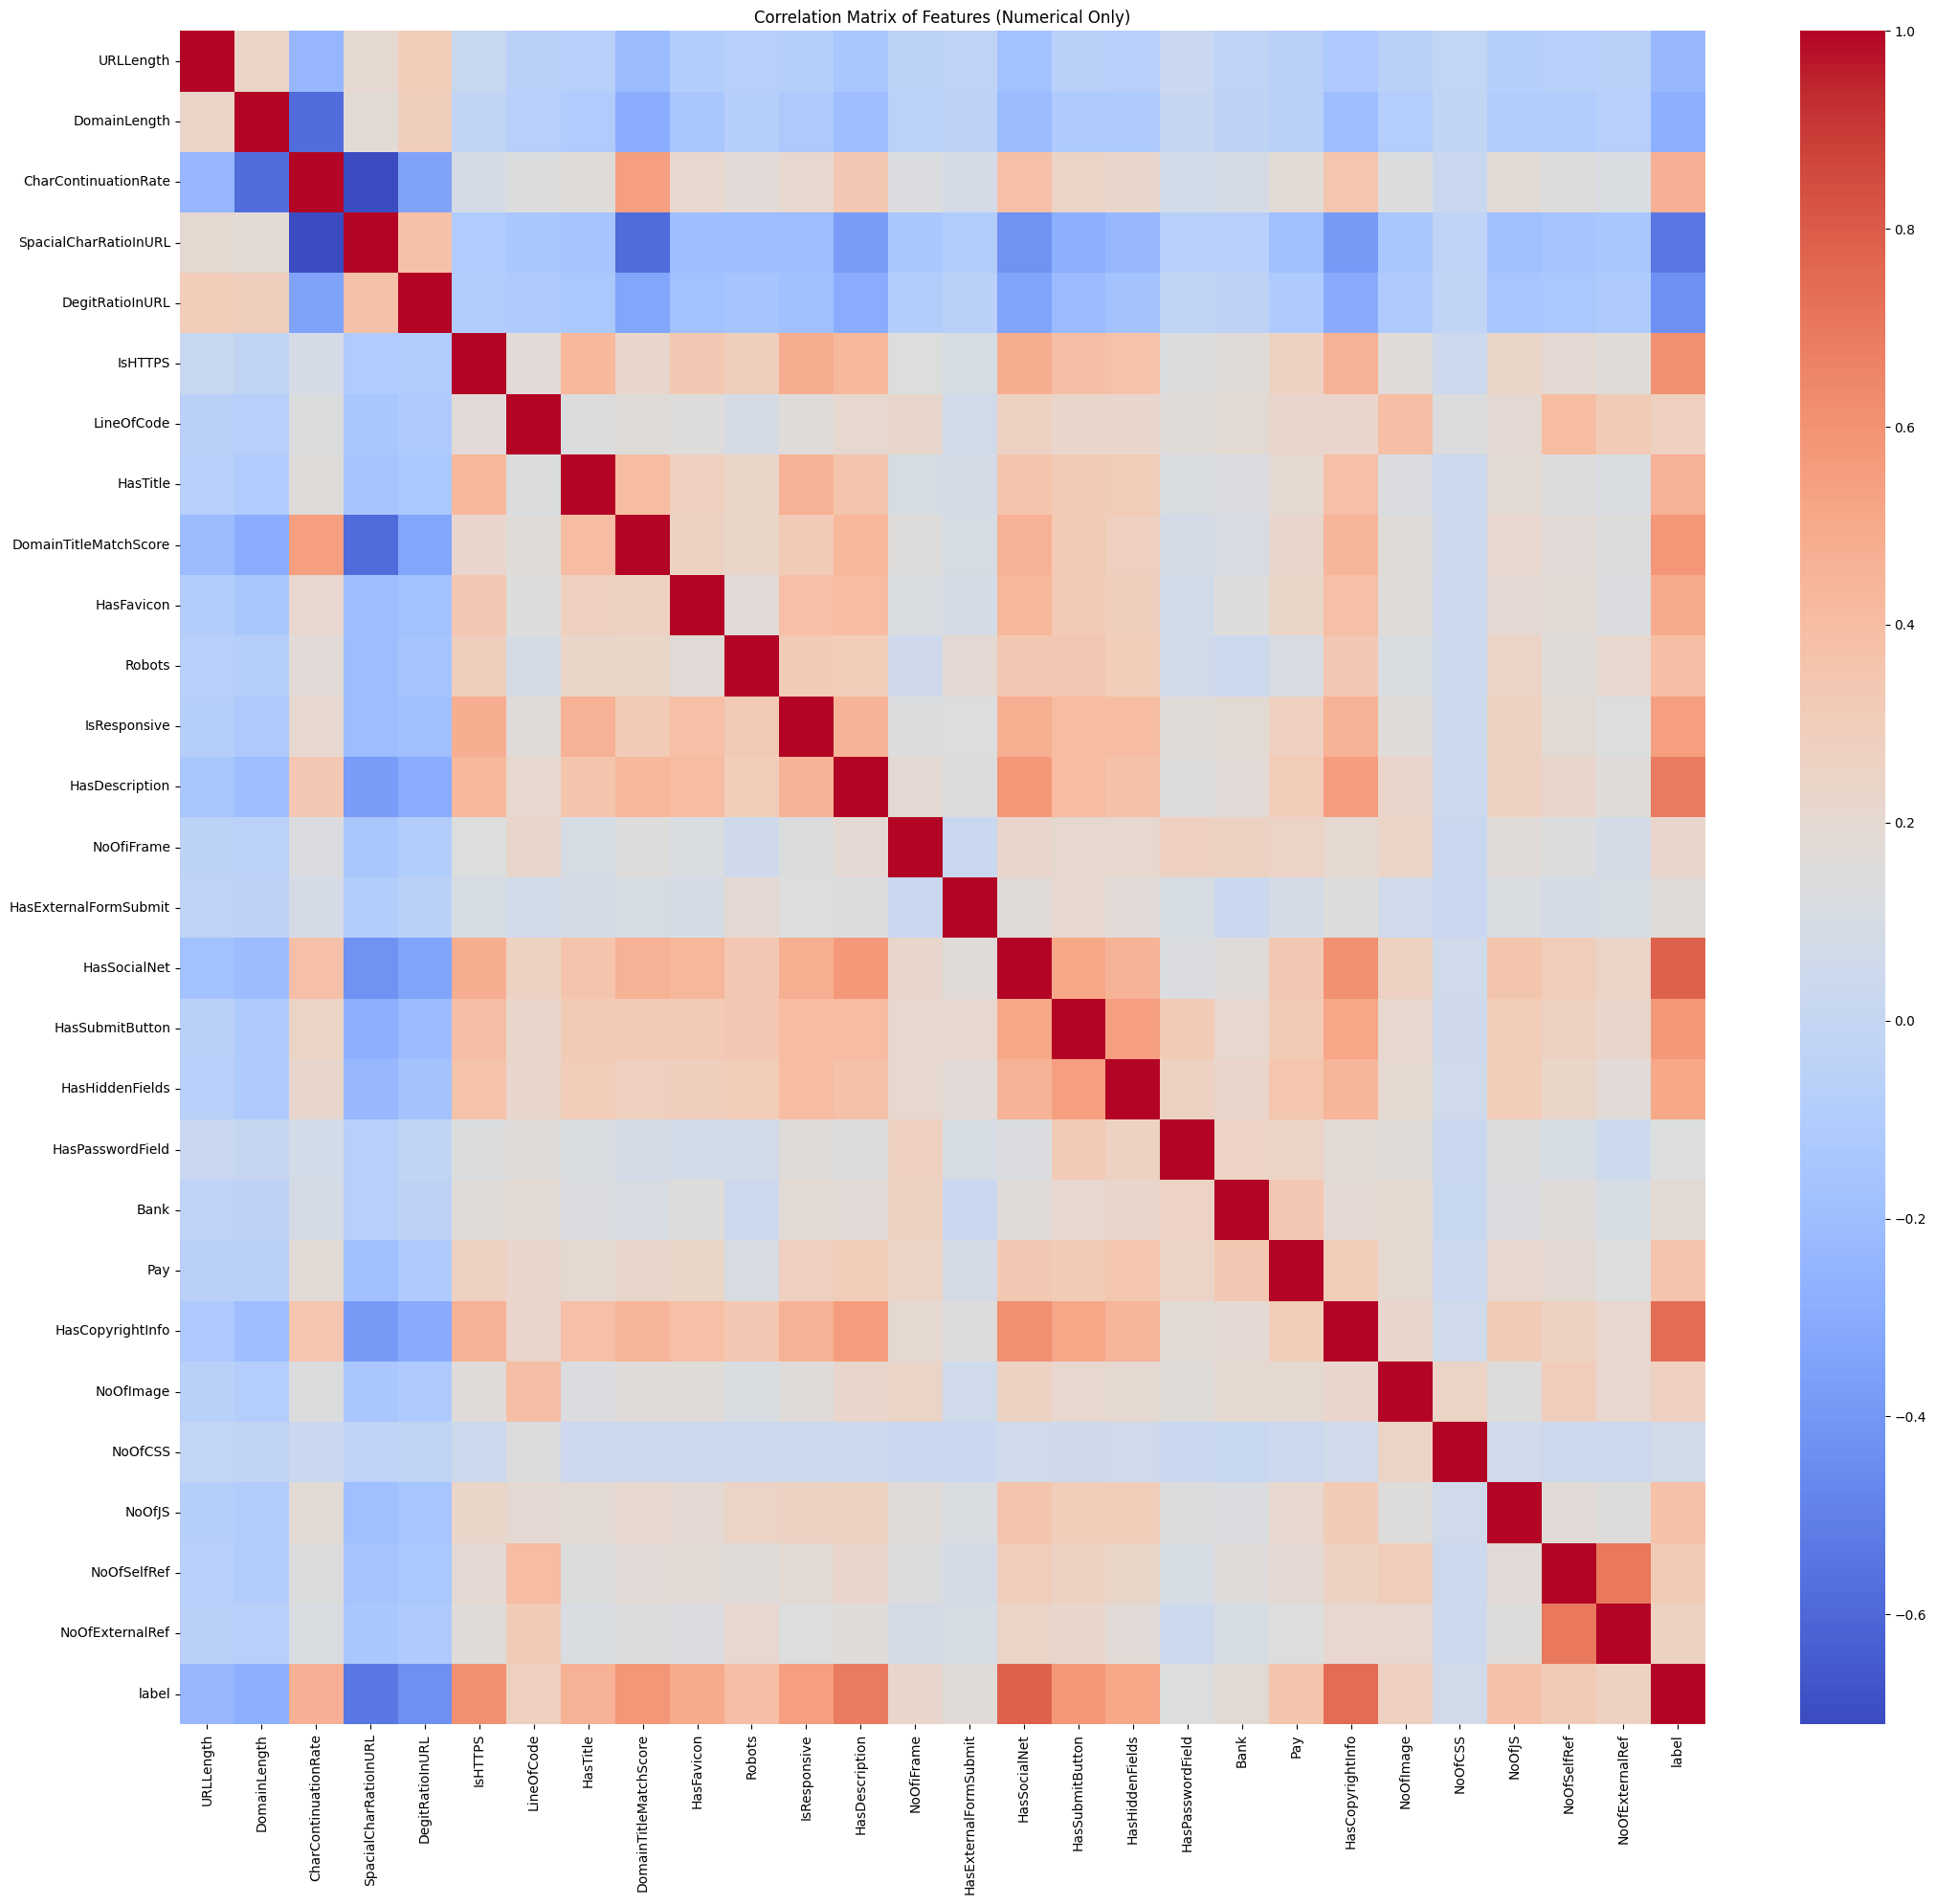

Correlation Matrix Heatmap saved as 'correlation_matrix.png'

--- Top Correlations with 'label' (Target) ---
label                    1.000000
HasSocialNet             0.784255
HasCopyrightInfo         0.743358
HasDescription           0.690232
IsHTTPS                  0.609132
DomainTitleMatchScore    0.584905
HasSubmitButton          0.578561
IsResponsive             0.548608
SpacialCharRatioInURL   -0.533537
HasHiddenFields          0.507731
HasFavicon               0.493711
CharContinuationRate     0.467735
HasTitle                 0.459725
DegitRatioInURL         -0.432032
Robots                   0.392620
NoOfJS                   0.373500
Pay                      0.359747
NoOfSelfRef              0.316211
DomainLength            -0.283152
NoOfImage                0.274658
LineOfCode               0.272257
NoOfExternalRef          0.258627
URLLength               -0.233445
NoOfiFrame               0.225822
Bank                     0.188959
HasExternalFormSubmit    0.167574
HasPass

In [4]:
# Cell 4
if df is not None:
    print("\n--- Generating Correlation Matrix Heatmap ---")

    # Features to drop for correlation matrix (non-numeric or non-feature columns)
    # Ensure this list aligns with what's dropped in model_train.py before numerical selection
    columns_to_drop_for_corr = ['URL', 'Domain', 'Title']
    
    # Also explicitly drop URLSimilarityIndex if it managed to creep in (should be removed by data_process.py)
    if 'URLSimilarityIndex' in df.columns:
        columns_to_drop_for_corr.append('URLSimilarityIndex')

    df_numeric_for_corr = df.drop(columns=columns_to_drop_for_corr, errors='ignore')

    # Handle potential NaNs by imputing with mean (for correlation calculation only)
    df_corr_imputed = df_numeric_for_corr.fillna(df_numeric_for_corr.mean(numeric_only=True))

    plt.figure(figsize=(22, 20))
    correlation_matrix = df_corr_imputed.corr(numeric_only=True)
    sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', fmt=".2f")
    plt.title('Correlation Matrix of Features (Numerical Only)')
    plt.tight_layout()
    plt.savefig('correlation_matrix.png')
    plt.show()
    print("Correlation Matrix Heatmap saved as 'correlation_matrix.png'")

    print("\n--- Top Correlations with 'label' (Target) ---")
    # Get correlations with the 'label' column
    # Sorting by absolute value to see strongest relationships, regardless of direction
    label_correlations = correlation_matrix['label'].sort_values(key=abs, ascending=False)
    print(label_correlations)
    print("\nInterpretation: Positive values mean higher feature value -> more likely to be Phishing (0).")
    print("Negative values mean higher feature value -> more likely to be Benign (1).")
    print("This is based on 0=Phishing, 1=Benign mapping in the original data, then interpreted by the model.")


--- Generating Feature-Label Bar Plots for Binary Features ---


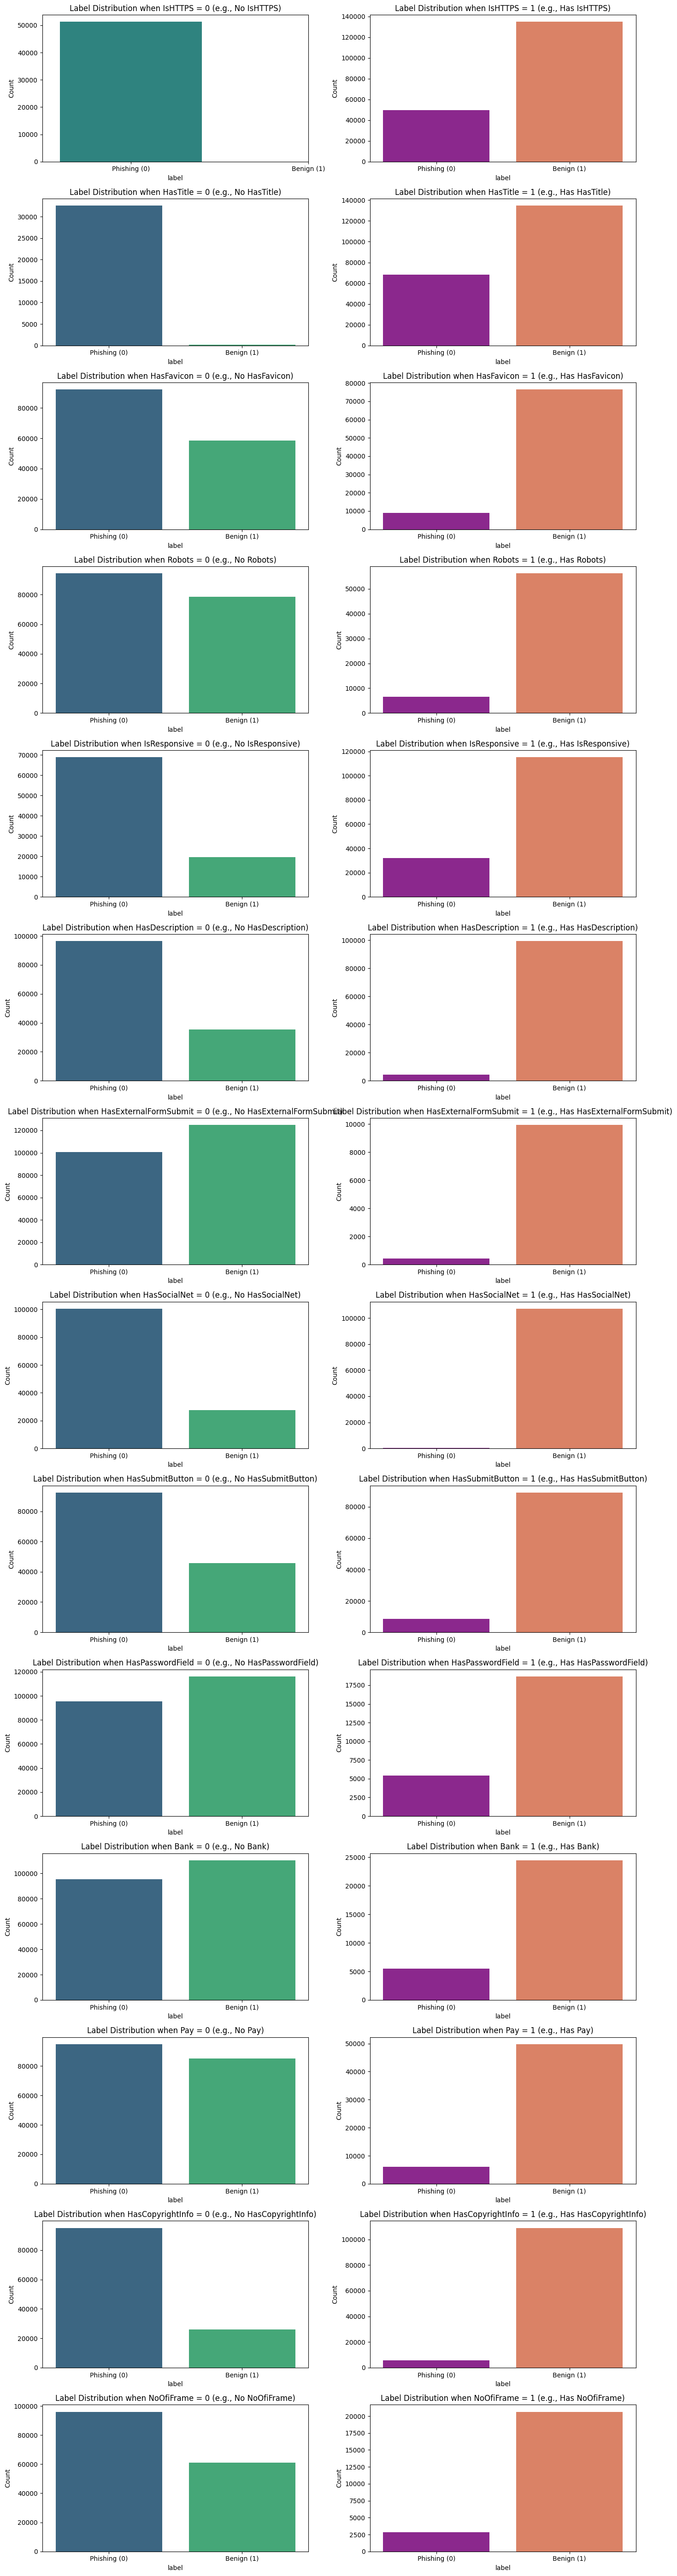

Binary Feature-Label Distributions saved as 'binary_feature_label_distribution.png'


In [5]:
# Cell 5
if df is not None:
    print("\n--- Generating Feature-Label Bar Plots for Binary Features ---")

    binary_features = [
        'IsDomainIP', 'HasObfuscation', 'IsHTTPS', 'HasTitle', 'HasFavicon',
        'Robots', 'IsResponsive', 'HasDescription', 'HasExternalFormSubmit',
        'HasSocialNet', 'HasSubmitButton', 'HasPasswordField', 'Bank', 'Pay',
        'Crypto', 'HasCopyrightInfo', 'NoOfPopup', 'NoOfiFrame'
    ]
    
    # Filter for features actually present in the DataFrame
    binary_features_present = [col for col in binary_features if col in df.columns]

    n_features = len(binary_features_present)
    fig, axes = plt.subplots(nrows=n_features, ncols=2, figsize=(14, 4 * n_features))
    
    if n_features == 1:
        axes = np.array([axes]).flatten()
    else:
        axes = axes.flatten()

    for i, feature in enumerate(binary_features_present):
        # Plot for feature = 0 (e.g., IsHTTPS = 0, meaning HTTP)
        # FIX: Assign 'x' to 'hue' and set 'legend=False'
        sns.countplot(x='label', data=df[df[feature] == 0], ax=axes[i*2], palette='viridis', hue='label', legend=False)
        axes[i*2].set_title(f'Label Distribution when {feature} = 0 (e.g., No {feature})')
        axes[i*2].set_xticks([0, 1])
        axes[i*2].set_xticklabels(['Phishing (0)', 'Benign (1)'])
        axes[i*2].set_ylabel('Count')

        # Plot for feature = 1 (e.g., IsHTTPS = 1, meaning HTTPS)
        # FIX: Assign 'x' to 'hue' and set 'legend=False'
        sns.countplot(x='label', data=df[df[feature] == 1], ax=axes[i*2 + 1], palette='plasma', hue='label', legend=False)
        axes[i*2 + 1].set_title(f'Label Distribution when {feature} = 1 (e.g., Has {feature})')
        axes[i*2 + 1].set_xticks([0, 1])
        axes[i*2 + 1].set_xticklabels(['Phishing (0)', 'Benign (1)'])
        axes[i*2 + 1].set_ylabel('Count')
            
    plt.tight_layout()
    plt.savefig('binary_feature_label_distribution.png')
    plt.show()
    print("Binary Feature-Label Distributions saved as 'binary_feature_label_distribution.png'")


--- Generating Feature-Label Distribution Plots for Numerical Features ---


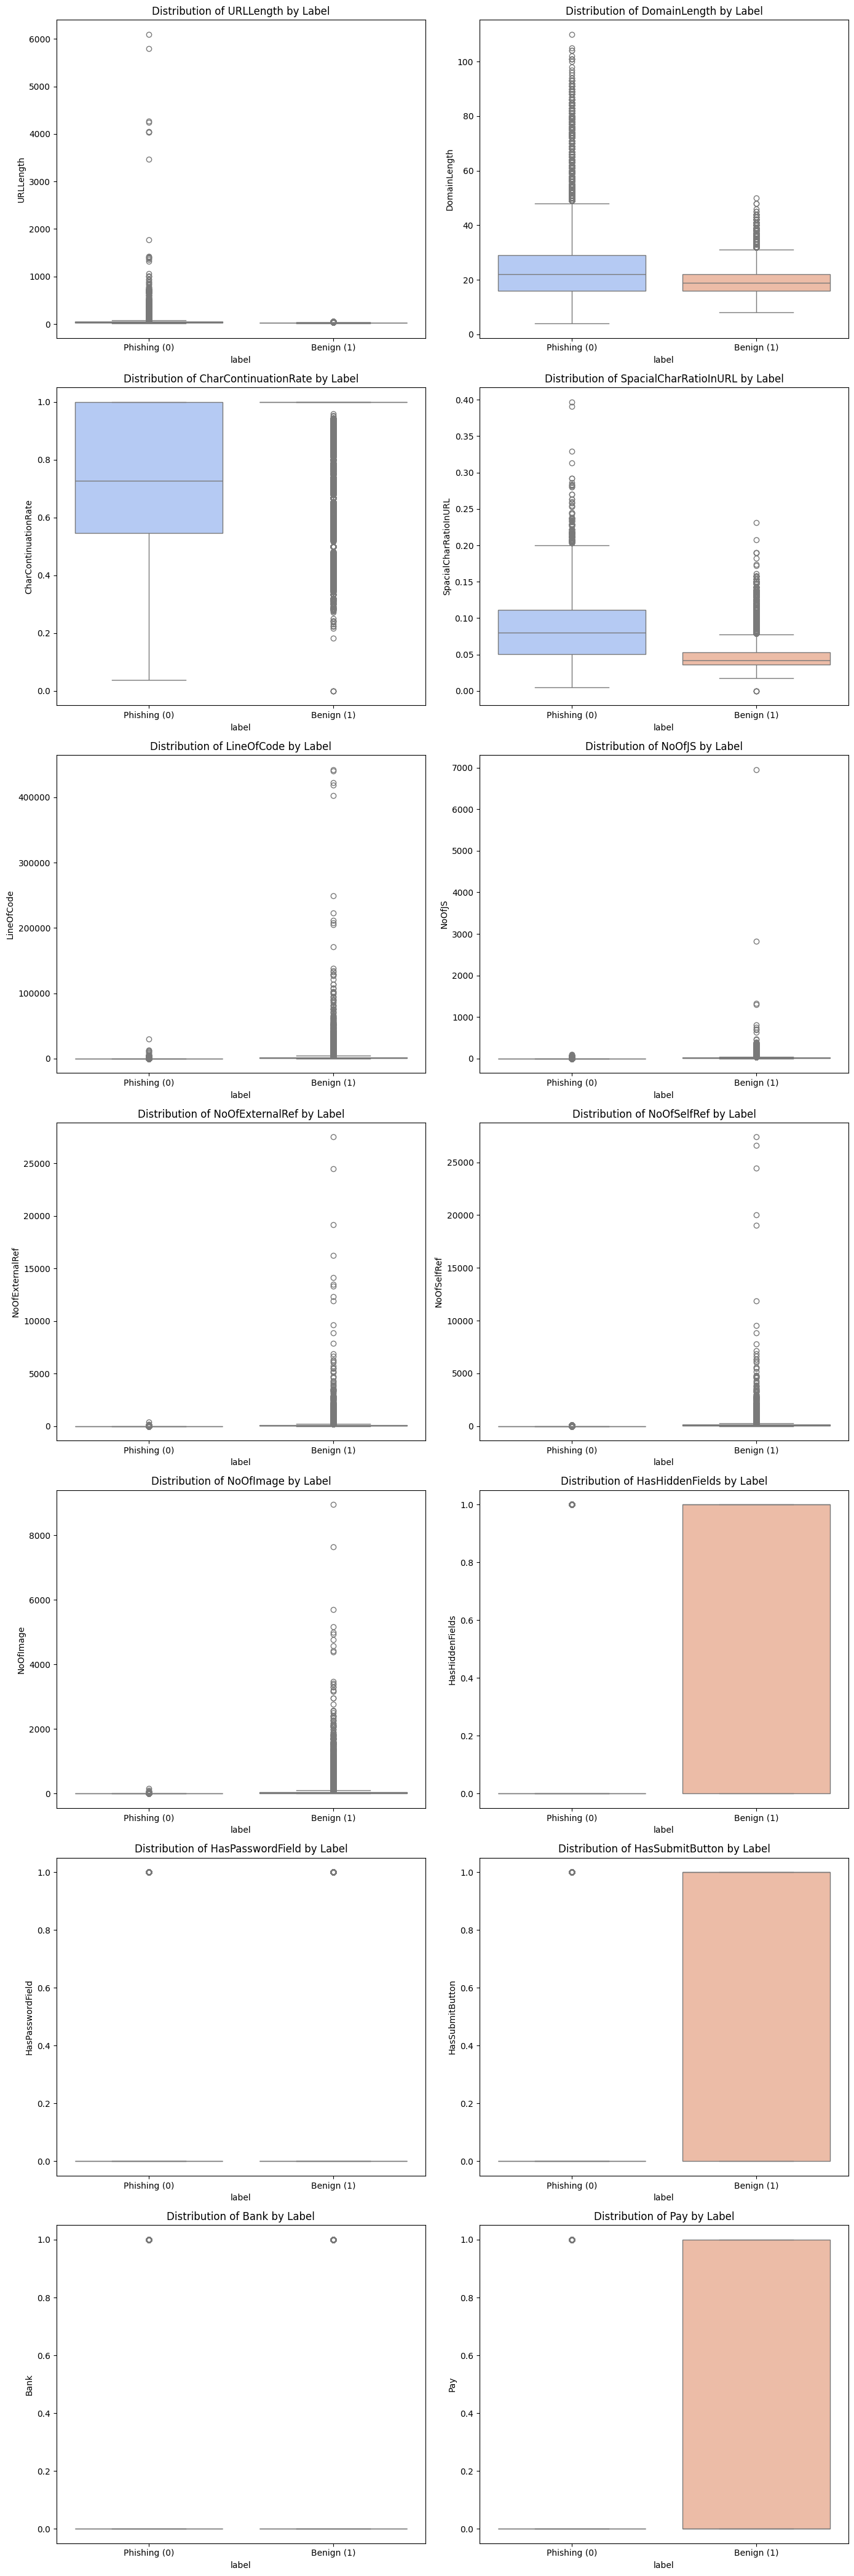

Numerical Feature-Label Distributions saved as 'numerical_feature_label_distribution.png'


In [6]:
# Cell 6
if df is not None:
    print("\n--- Generating Feature-Label Distribution Plots for Numerical Features ---")

    numerical_features = df.select_dtypes(include=np.number).columns.tolist()
    if 'label' in numerical_features:
        numerical_features.remove('label')
    
    selected_numerical_for_plot = [
        'URLLength', 'DomainLength', 'CharContinuationRate', 'SpacialCharRatioInURL',
        'LineOfCode', 'NoOfJS', 'NoOfExternalRef', 'NoOfSelfRef', 'NoOfImage',
        'HasHiddenFields', 'HasPasswordField', 'HasSubmitButton', 'Bank', 'Pay'
    ]
    
    selected_numerical_for_plot = [col for col in selected_numerical_for_plot if col in df.columns]

    if selected_numerical_for_plot:
        n_features_to_plot = len(selected_numerical_for_plot)
        n_rows = (n_features_to_plot + 1) // 2
        n_cols = 2

        fig_num, axes_num = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(14, 6 * n_rows))
        
        if n_features_to_plot == 1:
            axes_num = [axes_num.flatten()[0]]
        else:
            axes_num = axes_num.flatten()

        for i, feature in enumerate(selected_numerical_for_plot):
            if i < len(axes_num):
                # FIX: Assign 'x' to 'hue' and set 'legend=False'
                sns.boxplot(x='label', y=feature, data=df, ax=axes_num[i], palette='coolwarm', hue='label', legend=False)
                axes_num[i].set_title(f'Distribution of {feature} by Label')
                axes_num[i].set_xticks([0, 1])
                axes_num[i].set_xticklabels(['Phishing (0)', 'Benign (1)'])
                axes_num[i].set_ylabel(feature)
            
        for j in range(i + 1, len(axes_num)):
            fig_num.delaxes(axes_num[j])

        plt.tight_layout()
        plt.savefig('numerical_feature_label_distribution.png')
        plt.show()
        print("Numerical Feature-Label Distributions saved as 'numerical_feature_label_distribution.png'")
    else:
        print("No selected numerical features found for distribution plots.")

In [7]:
# Cell 7
if df is not None:
    print("\n--- Identifying Features with Low Absolute Correlation to 'label' ---")

    # Re-calculate correlation matrix (or use the one from Cell 4 if still in memory)
    # Ensure to drop non-numeric columns and impute NaNs as done for the heatmap
    columns_to_drop_for_corr = ['URL', 'Domain', 'Title']
    if 'URLSimilarityIndex' in df.columns:
        columns_to_drop_for_corr.append('URLSimilarityIndex')

    df_numeric_for_corr = df.drop(columns=columns_to_drop_for_corr, errors='ignore')
    df_corr_imputed = df_numeric_for_corr.fillna(df_numeric_for_corr.mean(numeric_only=True))
    correlation_matrix = df_corr_imputed.corr(numeric_only=True)

    # Get correlations with the 'label' column
    label_correlations = correlation_matrix['label'].drop('label') # Drop 'label' itself from its correlation list

    # Define a threshold for "low correlation"
    # You can adjust this threshold (e.g., 0.1, 0.05) based on your data and domain knowledge
    low_correlation_threshold = 0.1

    # Filter for features where the absolute correlation is below the threshold
    low_corr_features = label_correlations[abs(label_correlations) < low_correlation_threshold]

    if not low_corr_features.empty:
        print(f"\nFeatures with absolute correlation less than {low_correlation_threshold} to 'label':")
        print(low_corr_features.sort_values(key=abs, ascending=True).to_string())
        print("\nThese features are potential candidates for removal as they show a weak linear relationship with the target.")
    else:
        print(f"No features found with absolute correlation less than {low_correlation_threshold} to 'label'.")

    # Optional: Identify highly correlated features among themselves (for redundancy)
    print("\n--- Identifying Highly Inter-Correlated Features (Potential Redundancy) ---")
    # Exclude the label from this analysis
    features_only_corr = correlation_matrix.drop(columns=['label'], index=['label'])

    # Get the upper triangle of the correlation matrix to avoid duplicates
    upper_tri = features_only_corr.where(np.triu(np.ones(features_only_corr.shape), k=1).astype(bool))

    # Find pairs with correlation above a high threshold (e.g., 0.8 or 0.9)
    high_corr_threshold = 0.8
    high_corr_pairs = [(col, row, upper_tri.loc[row, col]) 
                       for col in upper_tri.columns for row in upper_tri.index 
                       if abs(upper_tri.loc[row, col]) > high_corr_threshold]

    if high_corr_pairs:
        print(f"\nFeature pairs with absolute correlation greater than {high_corr_threshold}:")
        for f1, f2, corr_val in sorted(high_corr_pairs, key=lambda x: abs(x[2]), reverse=True):
            print(f"- {f1} vs {f2}: {corr_val:.4f}")
        print("\nConsider removing one of these highly correlated features to reduce redundancy and simplify the model.")
    else:
        print(f"No feature pairs found with absolute correlation greater than {high_corr_threshold}.")


--- Identifying Features with Low Absolute Correlation to 'label' ---

Features with absolute correlation less than 0.1 to 'label':
NoOfCSS    0.068109

These features are potential candidates for removal as they show a weak linear relationship with the target.

--- Identifying Highly Inter-Correlated Features (Potential Redundancy) ---
No feature pairs found with absolute correlation greater than 0.8.
